# Unit 3 – Ex 1: Covariance and Pearson's correlation
Original code first, then experiments that change the data.

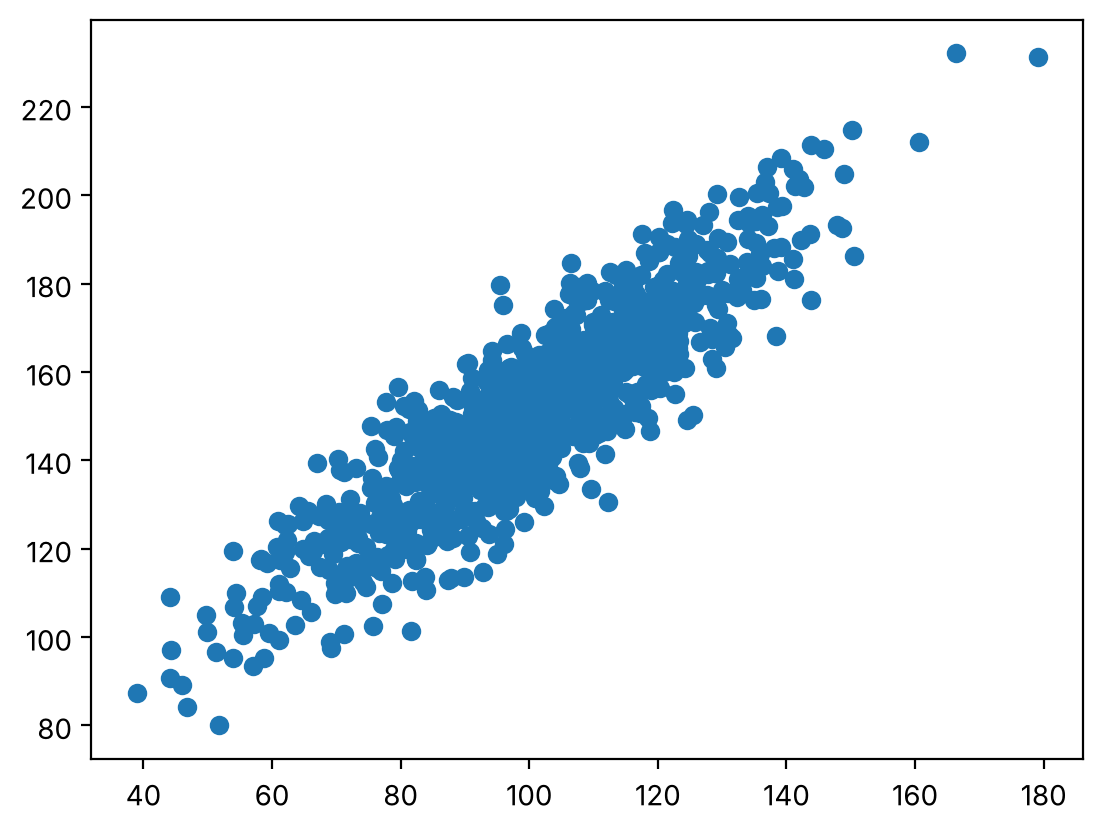

data1: mean=100.776 stdv=19.620
data2: mean=151.050 stdv=22.358
Covariance: 389.755
Pearsons correlation: 0.888


In [1]:
# calculate the Pearson's correlation between two variables (ORIGINAL)
from numpy import mean, std, cov
from numpy.random import randn, seed
from matplotlib import pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

seed(1)
data1 = 20 * randn(1000) + 100
data2 = data1 + (10 * randn(1000) + 50)

covariance = cov(data1, data2)
corr, _ = pearsonr(data1, data2)

plt.scatter(data1, data2)
plt.show()

print('data1: mean=%.3f stdv=%.3f' % (mean(data1), std(data1)))
print('data2: mean=%.3f stdv=%.3f' % (mean(data2), std(data2)))
print('Covariance: %.3f' % covariance[0][1])
print('Pearsons correlation: %.3f' % corr)

## Experiment 1 – Change the noise added to `data2`
The `10` in `10 * randn(1000)` sets how much random noise is added. More noise should weaken the relationship.

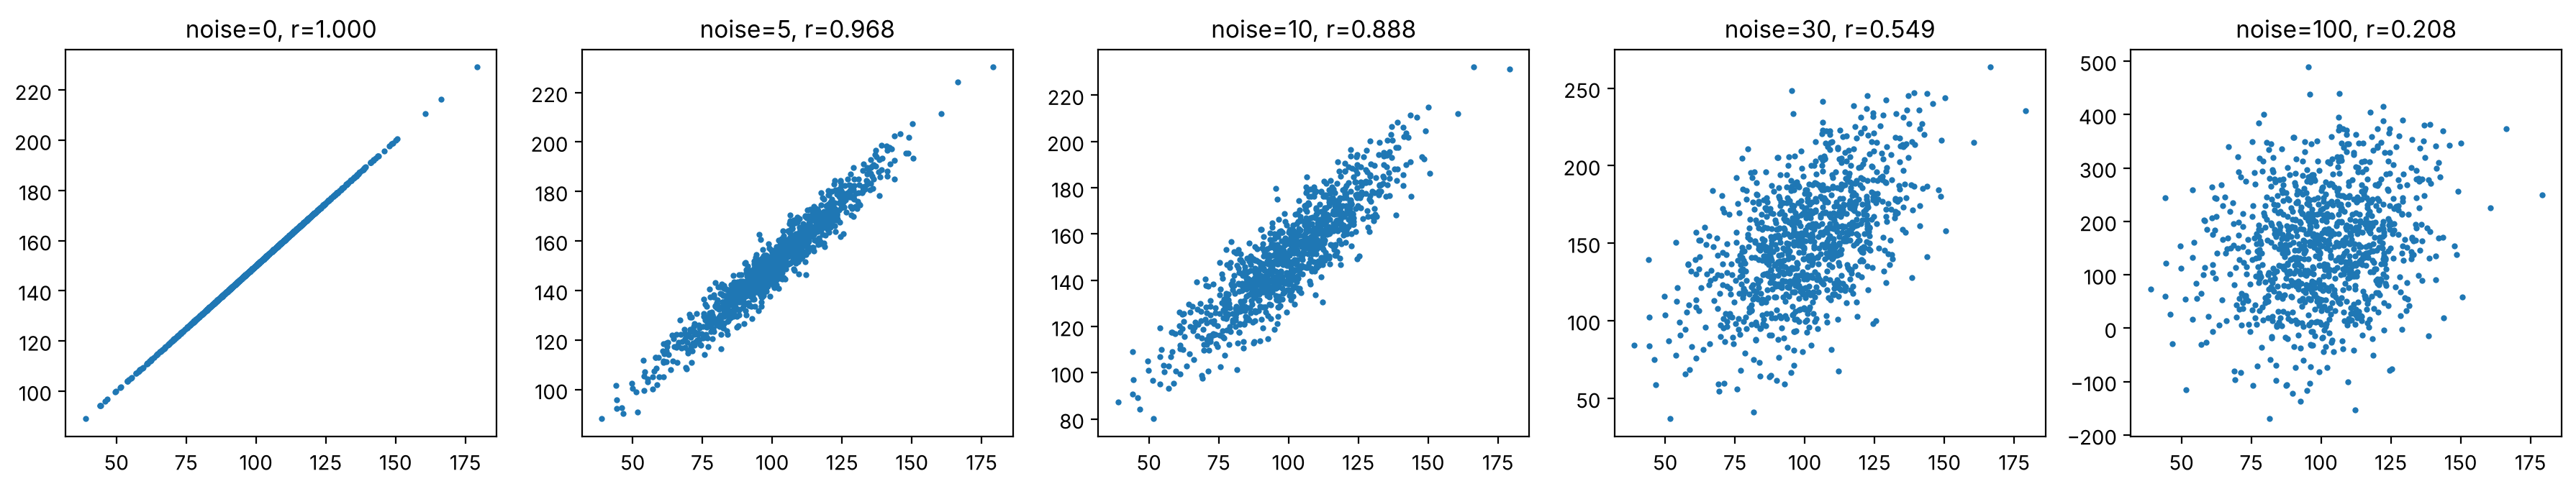

,noise sd,covariance,pearson r
0,0,385.333,1.000
1,5,387.544,0.968
2,10,389.755,0.888
3,30,398.598,0.549
4,100,429.549,0.208


In [2]:
import numpy as np
import pandas as pd

rows = []
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, noise in zip(axes, [0, 5, 10, 30, 100]):
    seed(1)
    d1 = 20 * randn(1000) + 100
    d2 = d1 + (noise * randn(1000) + 50)
    r, p = pearsonr(d1, d2)
    rows.append({'noise sd': noise, 'covariance': cov(d1, d2)[0][1], 'pearson r': r})
    ax.scatter(d1, d2, s=4); ax.set_title(f'noise={noise}, r={r:.3f}')
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

## Experiment 2 – Change the number of data points
With few points, the r value you get depends a lot on chance. Here each sample size is drawn 200 times to show how much r moves around.

In [3]:
rows = []
for n in [5, 10, 30, 100, 1000]:
    rs = []
    for s in range(200):
        seed(s)
        d1 = 20 * randn(n) + 100
        d2 = d1 + (10 * randn(n) + 50)
        rs.append(pearsonr(d1, d2)[0])
    rows.append({'n points': n, 'mean r': np.mean(rs), 'min r': np.min(rs), 'max r': np.max(rs)})
pd.DataFrame(rows).round(3)

,n points,mean r,min r,max r
0,5,0.870,-0.300,0.998
1,10,0.885,0.414,0.991
2,30,0.894,0.790,0.974
3,100,0.893,0.824,0.936
4,1000,0.894,0.875,0.913


## Experiment 3 – Rescale the data (change units)
Covariance depends on the units, so it changes. Pearson's r has no units, so it stays the same.

In [4]:
seed(1)
d1 = 20 * randn(1000) + 100
d2 = d1 + (10 * randn(1000) + 50)
for k in [1, 10, 1000]:
    print(f'data1 x {k:>4}:  covariance = {cov(d1*k, d2)[0][1]:>12.3f}   r = {pearsonr(d1*k, d2)[0]:.3f}')

data1 x    1:  covariance =      389.755   r = 0.888
data1 x   10:  covariance =     3897.546   r = 0.888
data1 x 1000:  covariance =   389754.562   r = 0.888


## Experiment 4 – Negative, non-linear and outlier cases

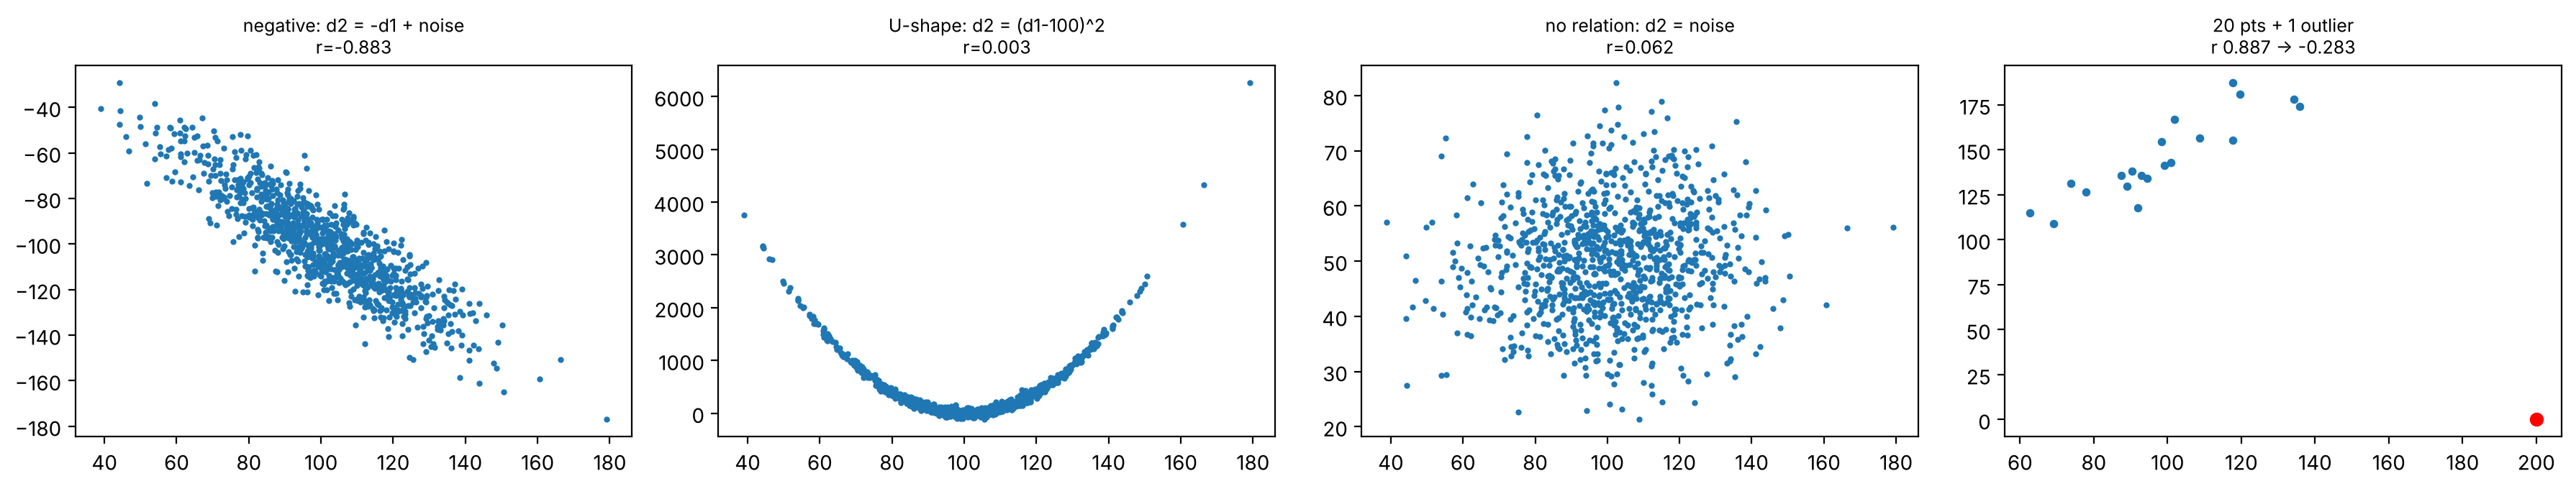

In [5]:
seed(1)
d1 = 20 * randn(1000) + 100
cases = {
    'negative: d2 = -d1 + noise': -d1 + 10 * randn(1000),
    'U-shape: d2 = (d1-100)^2':   (d1 - 100) ** 2 + 50 * randn(1000),
    'no relation: d2 = noise':     10 * randn(1000) + 50,
}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (name, d2) in zip(axes, cases.items()):
    r = pearsonr(d1, d2)[0]; ax.scatter(d1, d2, s=4); ax.set_title(f'{name}\nr={r:.3f}', fontsize=9)

# small sample + one outlier
seed(3)
x = 20 * randn(20) + 100; y = x + 10 * randn(20) + 50
r_before = pearsonr(x, y)[0]
x_o = np.append(x, 200); y_o = np.append(y, 0)
r_after = pearsonr(x_o, y_o)[0]
axes[3].scatter(x_o, y_o, s=10); axes[3].scatter([200], [0], c='red')
axes[3].set_title(f'20 pts + 1 outlier\nr {r_before:.3f} -> {r_after:.3f}', fontsize=9)
plt.tight_layout(); plt.show()

### What changed
* **Noise:** r goes from 1.0 with no noise down to about 0.2 at noise=100, while the actual link between the two variables stays the same.
* **Sample size:** with 5 points r can come out anywhere in a wide range. With 1000 points it settles near the true value.
* **Units:** multiplying data1 by 1000 multiplies the covariance by 1000 but leaves r the same. That's why r is used to compare strength, not covariance.
* **Shape:** a perfect U-shaped relationship gives r ≈ 0. Pearson only picks up *linear* relationships, so always plot the data first.
* **Outliers:** one bad point in a small sample can flip r from strongly positive to negative.